# Notebook 06: Division Events — How Their Spacing Shapes the Dynamics

**Goal:** Derive division events from an environment that records the system, then vary the
time between records and watch the same qubit move from indivisible, to divisible (a Markov chain at
the record times), to nearly frozen.

By the end of this notebook you will be able to:
- Derive a division event from a full system-plus-environment unitary, with no extra postulate
- Predict the dynamics for any record spacing δt from one number, ωδt
- Locate the spacing below which the process is divisible over every interval
- Show that imperfect records no longer guarantee division events, and measure when they fail

**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
  §3.7, "Division events and the Markov approximation", is the section this notebook simulates.
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference.

In [1]:
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.stochastic import PairwiseProcess
from isp.divisibility import check_divisibility_lp

## 1. Division Events From an Eavesdropping Environment

System: a qubit with configurations 0 and 1 and $H = \frac{\omega}{2}\sigma_x$. Time is in units of $1/\omega$.

Environment: a supply of fresh qubits, all starting in 0. At each time $t = k\,\delta t$, environment
qubit $k$ records the system's configuration: it is left in $|e_0\rangle$ if the system is in 0 and
$|e_1\rangle$ if it is in 1. The record quality is the overlap $c = \langle e_0 | e_1 \rangle$:
$c = 0$ is a perfect record, $c = 1$ is no record at all.

Paper 1, §3.7, eqs. 57–58: with perfect records at spacing $\delta t$,

$$\Gamma(n\delta t \leftarrow 0) = \Gamma_{\delta t}^{\,n}, \qquad \Gamma_{\delta t} = |U(\delta t)|^2,$$

which is a discrete-time Markov chain. Between records the qubit's own dynamics takes over:

$$\Gamma(t \leftarrow 0) = |U(t - k\delta t)|^2\,\Gamma_{\delta t}^{\,k}, \qquad k = \lfloor t/\delta t \rfloor.$$

Every matrix here has the form $\Gamma = \frac12\begin{pmatrix} 1+\lambda & 1-\lambda \\ 1-\lambda & 1+\lambda \end{pmatrix}$, so one number $\lambda(t)$
(the gap between the "started in 0" and "started in 1" columns) describes the whole process. The
closed form below is checked against a full unitary simulation of system plus environment.

The construction is Paper 1's own (§3.7). This section reproduces it; what it adds is the explicit simulation.

In [2]:
OMEGA = 1.0


def U(tau):
    # Qubit unitary for H = (OMEGA/2) sigma_x
    c, s = np.cos(OMEGA * tau / 2), np.sin(OMEGA * tau / 2)
    return np.array([[c, -1j * s], [-1j * s, c]])


def bloch(t, dt, c=0.0):
    # Bloch components (y, z) of the system started in 0, records every dt with overlap c.
    # Between records: rotation about x. At a record: coherence (y) multiplied by c.
    t = np.atleast_1d(np.asarray(t, float))
    if np.isinf(dt):
        return -np.sin(OMEGA * t), np.cos(OMEGA * t)
    k = np.floor(t / dt + 1e-9).astype(int)
    y_rec, z_rec = [0.0], [1.0]
    phi = OMEGA * dt
    for _ in range(k.max()):
        y, z = y_rec[-1], z_rec[-1]
        y_rec.append(c * (y * np.cos(phi) - z * np.sin(phi)))
        z_rec.append(y * np.sin(phi) + z * np.cos(phi))
    y0, z0, phi_t = np.array(y_rec)[k], np.array(z_rec)[k], OMEGA * (t - k * dt)
    return y0 * np.cos(phi_t) - z0 * np.sin(phi_t), y0 * np.sin(phi_t) + z0 * np.cos(phi_t)


def stretch(t, dt, c=0.0):
    # lambda(t) = Gamma_00(t <- 0) - Gamma_01(t <- 0)
    return bloch(t, dt, c)[1]


def gamma(t, dt, c=0.0):
    lam = stretch(t, dt, c)[0]
    return np.array([[1 + lam, 1 - lam], [1 - lam, 1 + lam]]) / 2


def gamma_environment(t, dt, n_env, c=0.0):
    # Gamma_S(t <- 0) from the full unitary on system + n_env environment qubits, then
    # marginalizing over environment configurations. Record k rotates environment qubit k
    # by Ry(theta) when the system is in 1, with cos(theta/2) = c.
    cr, sr = c, np.sqrt(1 - c ** 2)
    k = min(int(np.floor(t / dt + 1e-9)), n_env)
    G = np.zeros((2, 2))
    for j in (0, 1):
        psi = np.zeros((2,) * (1 + n_env), complex)
        psi[(j,) + (0,) * n_env] = 1
        for m in range(k):
            psi = np.tensordot(U(dt), psi, axes=([1], [0]))
            a0, a1 = psi[1].take(0, axis=m), psi[1].take(1, axis=m)
            psi[1] = np.stack([cr * a0 - sr * a1, sr * a0 + cr * a1], axis=m)
        psi = np.tensordot(U(t - k * dt), psi, axes=([1], [0]))
        G[:, j] = (np.abs(psi) ** 2).reshape(2, -1).sum(axis=1)
    return G


def divides(t_prime, t, dt, c=0.0):
    # Inverse-free test: does ANY valid stochastic Gamma(t <- t') exist?
    proc = PairwiseProcess(states=['0', '1'], times=[0.0, t_prime, t],
                           matrices={(0, 1): gamma(t_prime, dt, c), (0, 2): gamma(t, dt, c)})
    return check_divisibility_lp(proc)['divisible']

In [3]:
dt, n_env = 2.5, 6
ts = np.linspace(0, (n_env + 1) * dt, 70, endpoint=False)
for c in (0.0, 0.5):
    err = max(np.abs(gamma_environment(t, dt, n_env, c) - gamma(t, dt, c)).max() for t in ts)
    print(f'c = {c}: full system+environment simulation vs closed form, max error {err:.1e}')
print()

later = np.linspace(0.05, 15, 40)
for k in (1, 2, 3):
    t_prime = k * dt
    ok = all(divides(t_prime, t_prime + s, dt) for s in later)
    print(f"record time t' = {t_prime:4.1f}: a valid Gamma(t <- t') exists for every later t tested: {ok}")

t_prime, t = 1.5, 2.4
print(f"between records,  t' = {t_prime}, t = {t}: valid Gamma(t <- t') exists: {divides(t_prime, t, dt)}")

c = 0.0: full system+environment simulation vs closed form, max error 3.3e-16
c = 0.5: full system+environment simulation vs closed form, max error 5.6e-16

record time t' =  2.5: a valid Gamma(t <- t') exists for every later t tested: True
record time t' =  5.0: a valid Gamma(t <- t') exists for every later t tested: True
record time t' =  7.5: a valid Gamma(t <- t') exists for every later t tested: True
between records,  t' = 1.5, t = 2.4: valid Gamma(t <- t') exists: False


## 2. The Same Qubit at Five Record Spacings

With perfect records, $\lambda(t) = \cos(\omega\delta t)^{k}\,\cos\!\big(\omega(t - k\,\delta t)\big)$ and $P(0 \mid \text{started in } 0) = (1+\lambda)/2$.
Dashed: $|\cos\omega\delta t|^{\,t/\delta t}$, the exponential through the record-time values. Ticks on the axis: record times.

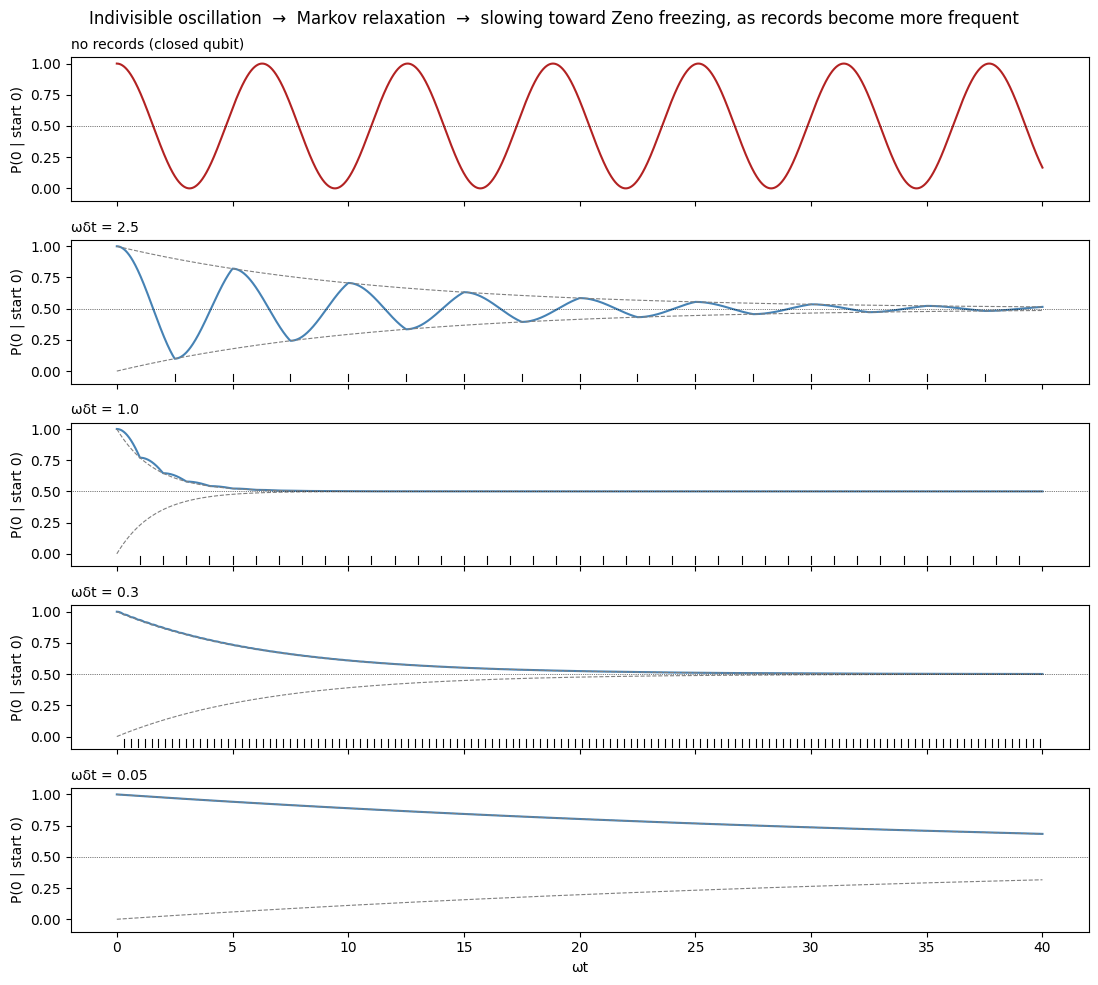

In [4]:
ts = np.linspace(0, 40, 4000)
spacings = [(np.inf, 'no records (closed qubit)'),
            (2.5, 'ωδt = 2.5'),
            (1.0, 'ωδt = 1.0'),
            (0.3, 'ωδt = 0.3'),
            (0.05, 'ωδt = 0.05')]

fig, axes = plt.subplots(len(spacings), 1, figsize=(11, 10), sharex=True)
for ax, (dt, label) in zip(axes, spacings):
    p = (1 + stretch(ts, dt)) / 2
    ax.plot(ts, p, color='firebrick' if np.isinf(dt) else 'steelblue')
    if not np.isinf(dt):
        env = np.abs(np.cos(OMEGA * dt)) ** (ts / dt)
        ax.plot(ts, (1 + env) / 2, '--', color='gray', lw=0.8)
        ax.plot(ts, (1 - env) / 2, '--', color='gray', lw=0.8)
        if dt >= 0.3:
            for tk in np.arange(dt, ts[-1], dt):
                ax.plot([tk, tk], [-0.08, -0.02], color='black', lw=0.8)
    ax.axhline(0.5, color='black', lw=0.5, ls=':')
    ax.set_ylim(-0.1, 1.05)
    ax.set_ylabel('P(0 | start 0)')
    ax.set_title(label, loc='left', fontsize=10)
axes[-1].set_xlabel('ωt')
plt.suptitle('Indivisible oscillation  →  Markov relaxation  →  slowing toward Zeno freezing, as records become more frequent')
plt.tight_layout()
plt.show()

## 3. Forgetting Rate Versus Spacing

Each record multiplies the record-time value of $|\lambda|$ by $|\cos\omega\delta t|$, so the relaxation rate is

$$\gamma(\delta t) = -\frac{\ln|\cos\omega\delta t|}{\delta t} \;\approx\; \frac{\omega^2\,\delta t}{2} \quad (\omega\delta t \ll 1).$$

Three landmarks:
- $\omega\delta t \to 0$: $\gamma \to 0$. Frequent perfect records freeze the configuration: the quantum Zeno effect (Misra and Sudarshan, 1977).
  $\gamma$ is the population-relaxation form of the repeated-measurement Zeno rate: twice the survival-probability rate
  $\omega^2\delta t/4$, because $\lambda$ is a population difference. Itano et al. (1990) measured the same $\cos^n$ product on a driven two-level transition of trapped ⁹Be⁺ ions.
- $\omega\delta t = \pi/2$: $\gamma = \infty$. Each record lands on a coin flip; one record erases the start.
- $\omega\delta t = \pi$: $\gamma = 0$. Each record lands when $|U(\delta t)|^2$ is a permutation. The records are
  transparent and the process is identical to the closed one. (Pimenta, arXiv:2505.08785, §V C, notes that every passage
  of $\Gamma$ through a permutation matrix is a "proper" division event.)

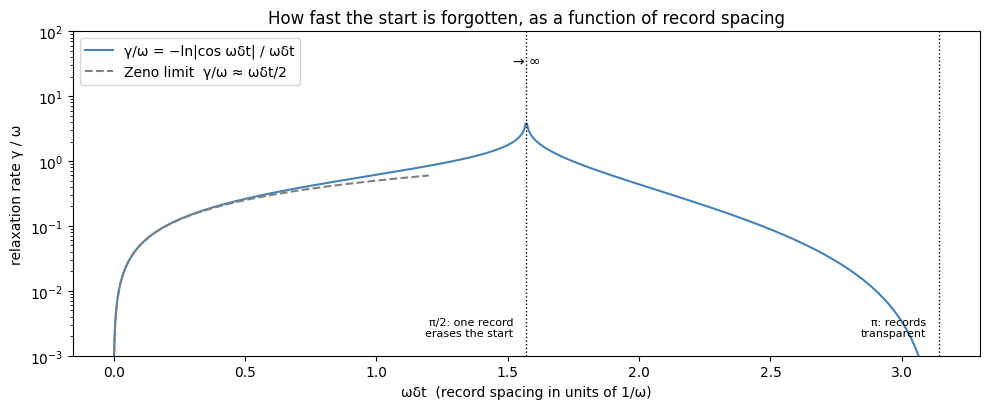

ωδt = π: max |λ_records − λ_closed| = 4.9e-15
ωδt = 0.3: γ/ω = 0.15231,  Zeno estimate 0.15000
ωδt = 0.05: γ/ω = 0.02501,  Zeno estimate 0.02500


In [5]:
x = np.linspace(1e-3, np.pi - 1e-3, 3000)
x = x[np.abs(x - np.pi / 2) > 2e-3]
rate = -np.log(np.abs(np.cos(x))) / x

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.semilogy(x, rate, color='steelblue', label='γ/ω = −ln|cos ωδt| / ωδt')
ax.semilogy(x[x < 1.2], x[x < 1.2] / 2, '--', color='gray', label='Zeno limit  γ/ω ≈ ωδt/2')
for xv, txt in [(np.pi / 2, 'π/2: one record\nerases the start'), (np.pi, 'π: records\ntransparent')]:
    ax.axvline(xv, color='black', ls=':', lw=1)
    ax.text(xv - 0.05, 2e-3, txt, ha='right', fontsize=8)
ax.set_xlabel('ωδt  (record spacing in units of 1/ω)')
ax.set_ylabel('relaxation rate γ / ω')
ax.set_ylim(1e-3, 1e2)
ax.annotate('→ ∞', xy=(np.pi / 2, 30), ha='center', fontsize=10)
ax.set_title('How fast the start is forgotten, as a function of record spacing')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

ts = np.linspace(0, 40, 2001)
print(f'ωδt = π: max |λ_records − λ_closed| = {np.abs(stretch(ts, np.pi) - stretch(ts, np.inf)).max():.1e}')
for xv in (0.3, 0.05):
    print(f'ωδt = {xv}: γ/ω = {-np.log(np.abs(np.cos(xv))) / xv:.5f},  Zeno estimate {xv / 2:.5f}')

## 4. Where Divisibility Holds

For this family, a valid $\Gamma(t \leftarrow t')$ exists exactly when $|\lambda(t)| \le |\lambda(t')|$: a stochastic step
cannot increase the distance between two distributions. (This rule needs no inverse, so it also
covers singular $\Gamma(t' \leftarrow 0)$.)

Records make every $k\,\delta t$ a conditioning time. Between records $|\lambda(t)| = |\lambda(k\delta t)|\,|\cos\omega\tau|$, with
$\tau = t - k\delta t$, which is non-increasing for $\omega\tau \le \pi/2$. Hence:

- $\omega\delta t \le \pi/2$: $|\lambda|$ never increases, and the process is divisible over **every** pair of times.
- $\omega\delta t > \pi/2$: $|\lambda|$ revives inside each interval, and indivisible pairs return.

**Prior work.** The threshold is known. The gap rule is the two-state case of Buscemi and Datta's theorem that a process
is divisible exactly when distinguishability never increases (Buscemi–Datta 2016, arXiv:1408.7062), and the $\pi/2$
threshold follows from it and from Pimenta's two-configuration analysis (arXiv:2505.08785).

largest invalid fraction for ωδt <= π/2: 0
invalid fraction with no records:        0.511
gap rule agrees with the LP test on 50 of 50 random pairs


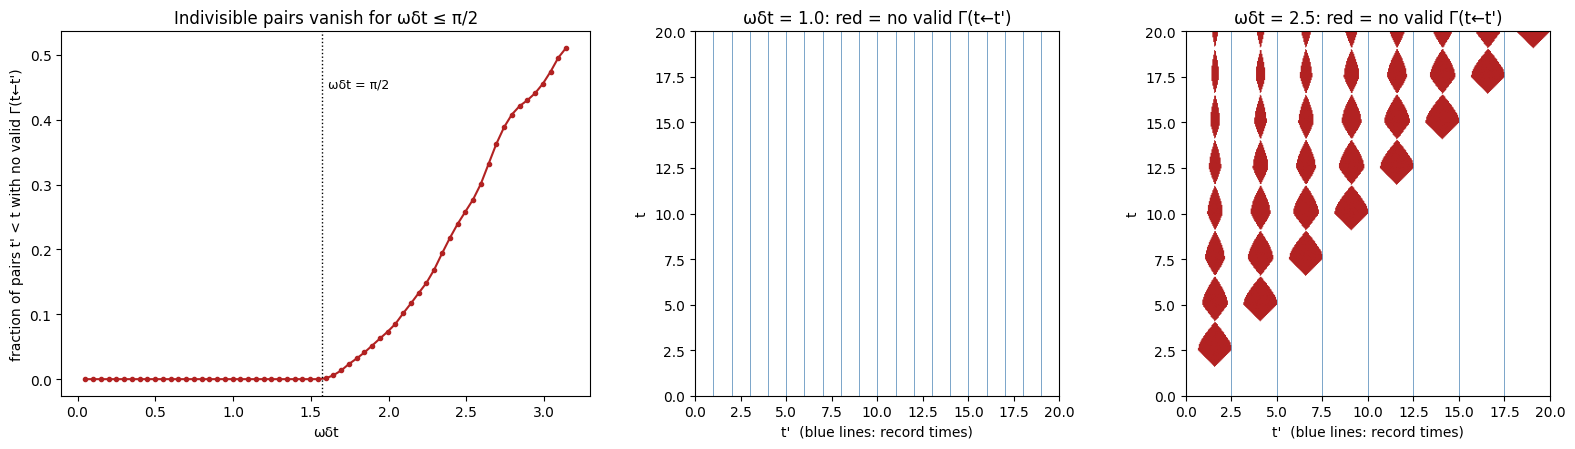

In [6]:
grid = np.linspace(0, 20, 401)
upper = np.triu(np.ones((grid.size, grid.size), bool), k=1)


def invalid_pairs(dt):
    L = np.abs(stretch(grid, dt))
    return (L[None, :] > L[:, None] + 1e-9) & upper     # row t', column t


x = np.linspace(0.05, np.pi, 63)
frac = [invalid_pairs(xv).sum() / upper.sum() for xv in x]
print(f'largest invalid fraction for ωδt <= π/2: {max(f for f, xv in zip(frac, x) if xv <= np.pi / 2 + 1e-12):.3g}')
print(f'invalid fraction with no records:        {invalid_pairs(np.inf).sum() / upper.sum():.3f}')

from matplotlib.colors import ListedColormap

rng = np.random.default_rng(6)
checks = []
for xv in (1.0, 2.5):
    bad = invalid_pairs(xv)
    for _ in range(25):
        i, j = sorted(rng.choice(grid.size, 2, replace=False))
        checks.append(divides(grid[i], grid[j], xv) == (not bad[i, j]))
print(f'gap rule agrees with the LP test on {sum(checks)} of {len(checks)} random pairs')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.3, 1, 1]})
axes[0].plot(x, frac, 'o-', ms=3, color='firebrick')
axes[0].axvline(np.pi / 2, color='black', ls=':', lw=1)
axes[0].text(np.pi / 2 + 0.04, 0.45, 'ωδt = π/2', fontsize=9)
axes[0].set_xlabel('ωδt'); axes[0].set_ylabel("fraction of pairs t' < t with no valid Γ(t←t')")
axes[0].set_title('Indivisible pairs vanish for ωδt ≤ π/2')
for ax, xv in zip(axes[1:], (1.0, 2.5)):
    ax.imshow(invalid_pairs(xv).T, origin='lower', extent=[0, 20, 0, 20],
              cmap=ListedColormap(['white', 'firebrick']), vmin=0, vmax=1)
    for tk in np.arange(xv, 20, xv):
        ax.axvline(tk, color='steelblue', lw=0.5)
    ax.set_xlabel("t'  (blue lines: record times)"); ax.set_ylabel('t')
    ax.set_title(f"ωδt = {xv}: red = no valid Γ(t←t')")
plt.tight_layout()
plt.show()

## 5. Imperfect Records

With overlap $c > 0$ a record only partly separates the environment's branches. The system's
coherence is multiplied by $c$ at each record instead of being erased, and the record times are no
longer guaranteed to be division events.

Measure the failure directly: after each record time $k\,\delta t$, how much distinguishability comes back,

$$R = \max_{k}\;\max_{t > k\delta t}\Big(|\lambda(t)| - |\lambda(k\,\delta t)|\Big)_{+}.$$

$R = 0$ means a valid $\Gamma(t \leftarrow k\,\delta t)$ exists from every record time checked (here the first 400 records); with
perfect records ($c = 0$) the record times are exact division events. $R > 0$ means some record time is not an exact division event.

Near the threshold the first failing record can come late (hundreds of records in), when $|\lambda|$ has already decayed, so
$R$ itself is tiny there. The threshold $c^*$ is therefore located with the relative revival
$\max_{t > k\delta t}|\lambda(t)|\,/\,|\lambda(k\delta t)| - 1$, which does not shrink as $|\lambda|$ decays, over the first 2000 records.
Since $|\lambda(t)|$ is the Kolmogorov distance between the runs started in 0 and in 1, $R$ is the maximal revival of that
distance after a record time: the classical memory witness of Smirne, Stabile and Vacchini (arXiv:1211.5913), evaluated
after record times.

**Prior work.** Barandes notes that division events are "generically always approximate" and become nearly exact when the
environment is sufficiently macroscopic (Paper 1, §3.7 and fn. 18, p. 19). Paper 3 (§2.2, p. 10) adds that they may be
"generated to an extremely good approximation through interactions with other systems." Whether a time is a
division event is a property of $\Gamma$ alone (Paper 2, eq. 35). Approximate division events, valid up to a stated level
of precision, are treated by Barandes, Hasan and Kagan (arXiv:2512.18105, §3.1). Measures of divisibility stated in
$\Gamma$ alone exist (Buscemi–Datta 2016, arXiv:1408.7062; Smirne, Stabile and Vacchini 2013, arXiv:1211.5913). Calvo
(arXiv:2601.18720, §5.1) ties exactness to a one-to-one match between environment and system configurations, and Smirne
et al. (2019, arXiv:1709.05267) give a related criterion for when repeated-measurement statistics are classical. Not found
in our searches: a physical sufficient condition on system plus environment, stated in transition probabilities, that
guarantees approximate division events at a given precision.

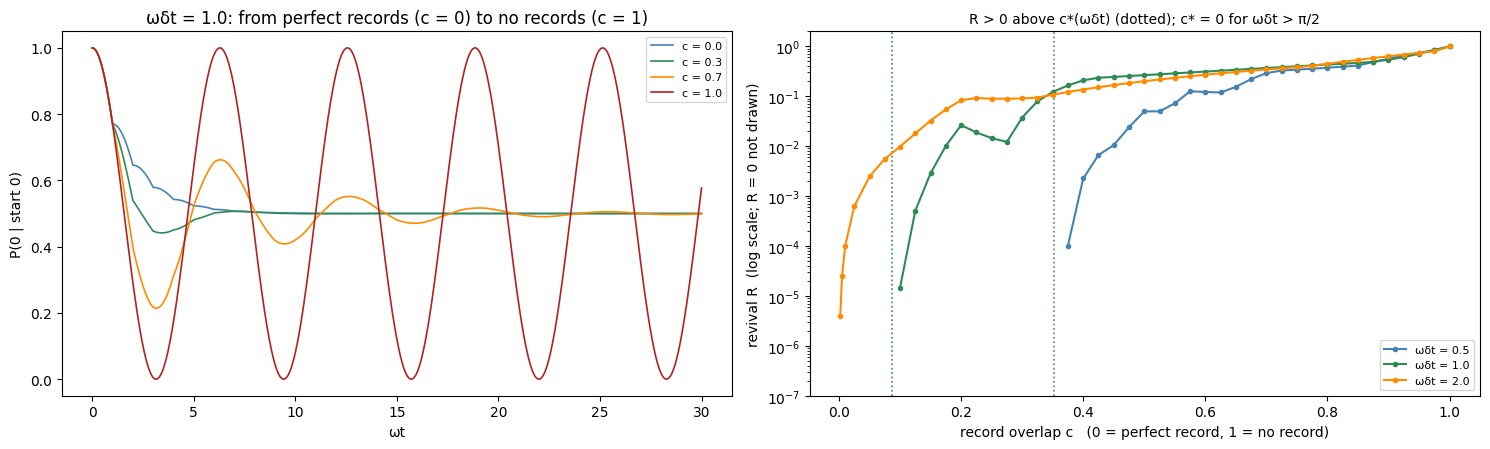

ωδt = 0.5: R(c=0) = 0.0e+00,  R(c=0.5) = 0.050,  R(c=1) = 1.000
ωδt = 1.0: R(c=0) = 0.0e+00,  R(c=0.5) = 0.265,  R(c=1) = 0.996
ωδt = 2.0: R(c=0) = 0.0e+00,  R(c=0.5) = 0.200,  R(c=1) = 0.996

threshold c* (largest c with R = 0), checking the first n records:
  ωδt = 0.3:  n = 8: 0.7194   n = 100: 0.5455   n = 2000: 0.5438
  ωδt = 0.5:  n = 8: 0.4310   n = 100: 0.3526   n = 2000: 0.3519


  ωδt = 1.0:  n = 8: 0.0986   n = 100: 0.0862   n = 2000: 0.0861
  ωδt = 1.5:  n = 8: 0.0014   n = 100: 0.0013   n = 2000: 0.0013

ωδt = 2.0, c = 0.01: R = 9.933e-05,  first-record estimate c² sin²ωδt / 2|cos ωδt| = 9.934e-05
ωδt = 2.0, c = 0.05: R = 2.476e-03,  first-record estimate c² sin²ωδt / 2|cos ωδt| = 2.484e-03


In [7]:
dt = 1.0
ts = np.linspace(0, 30, 3000)


def record_revivals(dt, c, n_records):
    # For record times k = 1..n: log of the largest |lambda(t)| over t >= k dt (up to the end of interval n),
    # and log |lambda(k dt)|. Working in logs, with rescaling, keeps long runs from underflowing.
    phi = OMEGA * dt
    y, z, log_s = 0.0, 1.0, 0.0                    # (y, z) * e^log_s = Bloch state just after the latest record
    log_peak, log_rec = [], []
    with np.errstate(divide='ignore'):
        for k in range(n_records + 1):
            # exact max of |z cos(tau) + y sin(tau)| over 0 <= tau <= phi: an endpoint, or the peak of |cos|
            alpha = np.arctan2(y, z) % np.pi
            peak = np.hypot(y, z) if alpha <= phi else max(abs(z), abs(z * np.cos(phi) + y * np.sin(phi)))
            log_peak.append(log_s + np.log(peak))
            log_rec.append(log_s + np.log(abs(z)))
            y, z = c * (y * np.cos(phi) - z * np.sin(phi)), y * np.sin(phi) + z * np.cos(phi)
            s = max(abs(y), abs(z))
            y, z, log_s = y / s, z / s, log_s + np.log(s)
    later = np.maximum.accumulate(np.array(log_peak)[::-1])[::-1]     # max over this and every later interval
    return later[1:], np.array(log_rec)[1:]


def revival(dt, c, n_records=400):
    # R over the first n_records record times
    later, rec = record_revivals(dt, c, n_records)
    return max((np.exp(later) - np.exp(rec)).max(), 0.0)


def blur_threshold(dt, n_records=2000, tol=1e-9):
    # Smallest c at which some record time fails, using the relative revival (scale-free)
    def fails(c):
        later, rec = record_revivals(dt, c, n_records)
        return np.expm1((later - rec).max()) > tol
    lo, hi = 0.0, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if not fails(mid) else (lo, mid)
    return hi


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for c, color in [(0.0, 'steelblue'), (0.3, 'seagreen'), (0.7, 'darkorange'), (1.0, 'firebrick')]:
    axes[0].plot(ts, (1 + stretch(ts, dt, c)) / 2, color=color, lw=1.2, label=f'c = {c}')
axes[0].set_xlabel('ωt'); axes[0].set_ylabel('P(0 | start 0)')
axes[0].set_title('ωδt = 1.0: from perfect records (c = 0) to no records (c = 1)')
axes[0].legend(fontsize=8)

cs = np.r_[0.002, 0.005, 0.01, np.linspace(0.025, 1, 40)]
for xv, color in [(0.5, 'steelblue'), (1.0, 'seagreen'), (2.0, 'darkorange')]:
    R = np.array([revival(xv, c) for c in cs])
    axes[1].semilogy(cs, np.where(R > 0, R, np.nan), 'o-', ms=3, color=color, label=f'ωδt = {xv}')
    if OMEGA * xv < np.pi / 2:
        axes[1].axvline(blur_threshold(xv), color=color, ls=':', lw=1.2)
axes[1].set_ylim(1e-7, 2)
axes[1].set_xlabel('record overlap c   (0 = perfect record, 1 = no record)')
axes[1].set_ylabel('revival R  (log scale; R = 0 not drawn)')
axes[1].set_title('R > 0 above c*(ωδt) (dotted); c* = 0 for ωδt > π/2', fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for xv in (0.5, 1.0, 2.0):
    print(f'ωδt = {xv}: R(c=0) = {revival(xv, 0.0):.1e},  R(c=0.5) = {revival(xv, 0.5):.3f},  R(c=1) = {revival(xv, 1.0):.3f}')
print()
print('threshold c* (largest c with R = 0), checking the first n records:')
for xv in (0.3, 0.5, 1.0, 1.5):
    print(f'  ωδt = {xv}:  n = 8: {blur_threshold(xv, 8):.4f}   n = 100: {blur_threshold(xv, 100):.4f}'
          f'   n = 2000: {blur_threshold(xv, 2000):.4f}')
print()
for c in (0.01, 0.05):
    print(f'ωδt = 2.0, c = {c}: R = {revival(2.0, c):.3e},  first-record estimate c² sin²ωδt / 2|cos ωδt| = '
          f'{c ** 2 * np.sin(2.0) ** 2 / (2 * abs(np.cos(2.0))):.3e}')

## Summary

- A recording environment produces division events with no extra postulate: the full unitary on
  system plus environment, marginalized, gives a transition matrix that divides at every record time.
  This reproduces Paper 1, §3.7.
- With perfect records every $\delta t$ the process is a Markov chain at the record times (Paper 1, eq. 57),
  and one number, $\omega\delta t$, sets its behaviour.
- $\omega\delta t \le \pi/2$: divisible over every pair of times. $\omega\delta t > \pi/2$: indivisible between records.
- The relaxation rate $-\ln|\cos\omega\delta t|/\delta t$ is not monotone in the record rate. It vanishes as
  $\delta t \to 0$ (Zeno), diverges at $\omega\delta t = \pi/2$, and vanishes again at $\omega\delta t = \pi$, where the records are transparent.
- Imperfect records ($c > 0$) no longer guarantee division events. For $\omega\delta t < \pi/2$ the record times keep dividing
  up to a threshold $c^*(\omega\delta t)$, about 0.54 at $\omega\delta t = 0.3$, 0.35 at 0.5, 0.086 at 1.0 and 0.0013 at 1.5, falling to 0
  as $\omega\delta t \to \pi/2$. For $\omega\delta t > \pi/2$ any $c > 0$ makes them fail, though only weakly: for small $c$ the first record already gives
  $R \approx c^2\sin^2\omega\delta t\,/\,2|\cos\omega\delta t|$. Paper 1 (fn. 18) anticipates that division events are generically approximate.

Caveat: the Zeno freezing follows from *ideal, instantaneous, configuration-basis* records in this
two-state model. How smooth classical motion survives very frequent, realistic (coarse-grained,
imperfect) records is not addressed here.

**Prior work.** None of the results here is new. Records making division events is Paper 1's own construction (§3.7).
The forgetting rate is the population-relaxation form of the repeated-measurement Zeno rate (Misra and Sudarshan, 1977;
Itano et al., 1990). The $\omega\delta t \le \pi/2$ threshold follows from Buscemi and Datta's divisibility criterion
(Buscemi–Datta 2016) and from Pimenta (arXiv:2505.08785). The revival $R$ is Smirne, Stabile and Vacchini's
Kolmogorov-distance witness (arXiv:1211.5913). That division events are approximate is Barandes's own point (Paper 1,
fn. 18), and approximate division events at a stated precision appear in Barandes, Hasan and Kagan (arXiv:2512.18105, §3.1).
What the notebook adds is a worked, fully simulated example.